<a href="https://colab.research.google.com/github/kinyanjui23/resnet/blob/main/ResNet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Building a convolutional neural network with residual connections and train it on CIFAR-10 and focus on understanding the architecture and validating every stage of the training pipeline.

A plain stack of layers learns a mapping from an input tensor to an output tensor. A residual block instead learns a residual function and adds the original input back:
$$
y = F(x; \theta) + x
$$
Here:
- $(x) is  the input feature map.$
- $$(F(x; \theta)) is the transformation learned by convolutional layers and their associated operations. $$
- $$(\theta) represents the trainable parameters. $$
- $$(y) is the block output. $$  

We are importing libraries that'll help in developing our framework.

In [47]:
import copy
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torch.utils.data import random_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

Preparing our data by loading it and making it ready to be fed to our framework

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))])

In [5]:
train_set = datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
test_set = datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

100%|██████████| 170M/170M [08:16<00:00, 343kB/s]


In [7]:
PIN_MEMORY = torch.cuda.is_available()

In [8]:
BATCH_SIZE = 128
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, pin_memory=PIN_MEMORY)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, pin_memory=PIN_MEMORY)

In [13]:
train_size = 45000
val_size = 5000
train, val = random_split(train_set, [train_size, val_size])
train_loader = DataLoader(train, batch_size=BATCH_SIZE, shuffle=True, pin_memory=PIN_MEMORY)
val_loader = DataLoader(val, batch_size=BATCH_SIZE, shuffle=False, pin_memory=PIN_MEMORY)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False, pin_memory=PIN_MEMORY)

## Define the residual block
Our basic block uses two $(3 \times 3)$ convolutions. Each convolution is followed by batch normalization; ReLU is applied after the first convolution and after the residual addition.

For an input tensor of shape $((N, C_{in}, H, W))$, a convolution's output dimensions depend on its kernel size, padding, and stride. With a $(3 \times 3)$ kernel, padding 1, and stride 1, height and width are preserved.

If the block changes the number of channels or reduces spatial dimensions, the shortcut uses a $(1 \times 1)$ projection convolution. This makes the two paths compatible for addition.

In [26]:
class ResidualBlock(nn.Module):
  def __init__(self, in_channels, out_channels, stride=1):
    super().__init__()
    self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
    self.bn1 = nn.BatchNorm2d(out_channels)
    self.relu = nn.ReLU(inplace=True)

    self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
    self.bn2 = nn.BatchNorm2d(out_channels)

    # Identity shortcut when shapes match; projection otherwise.
    if stride != 1 or in_channels != out_channels:
      self.shortcut = nn.Sequential(
          nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
          nn.BatchNorm2d(out_channels)
      )
    else:
      self.shortcut = nn.Identity()


  def forward(self, x):
    identity = self.shortcut(x)

    out = self.conv1(x)
    out = self.bn1(out)
    out = self.relu(out)

    out = self.conv2(out)
    out = self.bn2(out)

    out = out + identity
    out = self.relu(out)


    return out

Build the Residual CNN
The network starts with a convolutional stem, then uses residual stages with increasing channel counts. The first block in later stages uses stride 2 to reduce spatial resolution while increasing channels.

For a batch of 128 images, the expected shape progression is:
Stage	Expected output shape
Input	(128, 3, 32, 32)
Stem	(128, 32, 32, 32)
Stage 1	(128, 32, 32, 32)
Stage 2	(128, 64, 16, 16)
Stage 3	(128, 128, 8, 8)
Global average pooling	(128, 128, 1, 1)
Flatten	(128, 128)
Classifier	(128, 10)

we use the formula: $$
 \boxed{[H_{out} = \frac{H_{in} + 2(P) - D(k-1) -1}{S} + 1
}\
$$

and for width:
$$
 \boxed{[W_{out} = \frac{W_{in} + 2(P) - D(k-1) -1}{S} + 1
}\
$$

In [30]:
class cresnet(nn.Module):
  def __init__(self, num_classes=10):
    super().__init__()
    self.stem = nn.Sequential(
        nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1, bias=False),
        nn.BatchNorm2d(32),
        nn.ReLU(inplace=True),
        nn.Conv2d(32, 32, kernel_size=3, stride=1, padding=1, bias=False),
        nn.BatchNorm2d(32),
        nn.ReLU(inplace=True),
    )

    self.stage1 = nn.Sequential(
        ResidualBlock(32, 32, stride=1),
        ResidualBlock(32, 32, stride=1)
    )

    self.stage2 = nn.Sequential(
        ResidualBlock(32, 64, stride=1),
        ResidualBlock(64, 64, stride=1)

    )

    self.stage3 = nn.Sequential(
        ResidualBlock(64, 128, stride=1),
        ResidualBlock(128, 128, stride=1)
    )

    self.pool = nn.AdaptiveAvgPool2d((1,1))
    self.classifier = nn.Linear(128, num_classes)


  def forward(self, x):
      x = self.stem(x)
      x = self.stage1(x)
      x = self.stage2(x)
      x = self.stage3(x)
      x = self.pool(x)
      x = torch.flatten(x, 1)
      x = self.classifier(x)
      return x



model = cresnet(num_classes=10).to(device)

print(model)
total_parms = sum(p.numel() for p in model.parameters())
print(f"total number of paramaters is : {total_parms}")

cresnet(
  (stem): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
  )
  (stage1): Sequential(
    (0): ResidualBlock(
      (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (shortcut): Identity()
    )
    (1): ResidualBlock(
      (conv1): Conv2d(32, 32, kernel_size=(3, 

In [31]:
model.eval()
sample_images, sample_labels = next(iter(train_loader))
sample_images = sample_images[:8].to(device)
sample_labels = sample_labels[:8].to(device)

with torch.no_grad():
    sample_logits = model(sample_images)

print("Input shape:", tuple(sample_images.shape))
print("Output logits shape:", tuple(sample_logits.shape))
print("Expected shape:", (8, 10))
print("Logits finite:", torch.isfinite(sample_logits).all().item())

assert sample_logits.shape == (8, 10)
assert torch.isfinite(sample_logits).all()

print("Forward-pass shape checks passed.")

Input shape: (8, 3, 32, 32)
Output logits shape: (8, 10)
Expected shape: (8, 10)
Logits finite: True
Forward-pass shape checks passed.


In [32]:
criterion = nn.CrossEntropyLoss()
LEARNING_RATE = 0.001
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

In [36]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += batch_size

    if total == 0:
        raise ValueError("Training loader produced no examples.")

    return running_loss / total, 100.0 * correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        logits = model(images)
        loss = criterion(logits, labels)

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += batch_size

    if total == 0:
        raise ValueError("Evaluation loader produced no examples.")

    return running_loss / total, 100.0 * correct / total

In [43]:
NUM_EPOCHS = 10

# Start a fresh main model for the recorded experiment.
model = cresnet(num_classes=10).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

history = {
    "training_loss": [],
    "val_loss": [],
    "training_acc": [],
    "val_acc": []
}

best_val_loss = float("inf")
best_model_state = copy.deepcopy(model.state_dict())

for epoch in range(NUM_EPOCHS):
    start_time = time.perf_counter()

    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )
    val_loss, val_acc = evaluate(
        model, val_loader, criterion, device
    )

    elapsed = time.perf_counter() - start_time

    history["training_loss"].append(float(train_loss))
    history["val_loss"].append(float(val_loss))
    history["training_acc"].append(float(train_acc))
    history["val_acc"].append(float(val_acc))

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())

    print(
        f"Epoch [{epoch + 1:02d}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}% | "
        f"Time: {elapsed:.1f}s"
    )

# Restore the checkpoint with the lowest validation loss.
model.load_state_dict(best_model_state)
print(f"Best validation loss: {best_val_loss:.4f}")

Epoch [01/10] | Train Loss: 1.3831 | Train Acc: 49.34% | Val Loss: 1.3388 | Val Acc: 53.14% | Time: 91.3s
Epoch [02/10] | Train Loss: 0.9937 | Train Acc: 64.67% | Val Loss: 1.4990 | Val Acc: 52.62% | Time: 94.7s
Epoch [03/10] | Train Loss: 0.8372 | Train Acc: 70.35% | Val Loss: 0.9677 | Val Acc: 67.24% | Time: 95.5s
Epoch [04/10] | Train Loss: 0.7356 | Train Acc: 74.31% | Val Loss: 1.4279 | Val Acc: 59.40% | Time: 95.4s
Epoch [05/10] | Train Loss: 0.6582 | Train Acc: 76.84% | Val Loss: 0.9768 | Val Acc: 65.80% | Time: 95.1s
Epoch [06/10] | Train Loss: 0.5914 | Train Acc: 79.54% | Val Loss: 0.7646 | Val Acc: 73.22% | Time: 95.3s
Epoch [07/10] | Train Loss: 0.5397 | Train Acc: 81.53% | Val Loss: 1.2877 | Val Acc: 64.08% | Time: 95.0s
Epoch [08/10] | Train Loss: 0.5023 | Train Acc: 82.55% | Val Loss: 0.6868 | Val Acc: 77.08% | Time: 95.3s
Epoch [09/10] | Train Loss: 0.4542 | Train Acc: 84.35% | Val Loss: 0.7737 | Val Acc: 74.40% | Time: 95.3s
Epoch [10/10] | Train Loss: 0.4206 | Train Acc

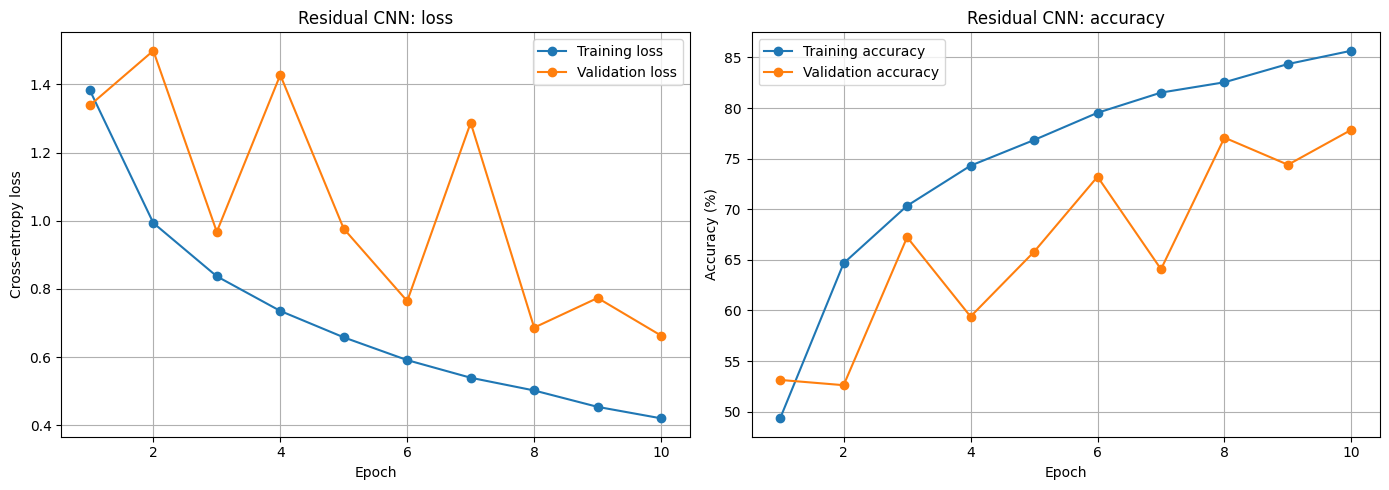

In [45]:
epochs = range(1, len(history["training_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, history["training_loss"], marker="o", label="Training loss")
axes[0].plot(epochs, history["val_loss"], marker="o", label="Validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].set_title("Residual CNN: loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs, history["training_acc"], marker="o", label="Training accuracy")
axes[1].plot(epochs, history["val_acc"], marker="o", label="Validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_title("Residual CNN: accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [51]:
test_loss, test_acc = evaluate(model, test_loader, criterion, device)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.2f}%")

all_predictions = []
all_targets = []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        logits = model(images)
        predictions = logits.argmax(dim=1).cpu().numpy()

        all_predictions.extend(predictions.tolist())
        all_targets.extend(labels.numpy().tolist())

print(classification_report(
    all_targets,
    all_predictions,
    target_names=test_set.classes,
    digits=3,
    zero_division=0
))

Test loss: 0.6747
Test accuracy: 77.97%
              precision    recall  f1-score   support

    airplane      0.707     0.885     0.786      1000
  automobile      0.833     0.935     0.881      1000
        bird      0.846     0.560     0.674      1000
         cat      0.733     0.517     0.606      1000
        deer      0.808     0.751     0.779      1000
         dog      0.856     0.582     0.693      1000
        frog      0.647     0.930     0.763      1000
       horse      0.749     0.885     0.811      1000
        ship      0.931     0.840     0.883      1000
       truck      0.808     0.912     0.857      1000

    accuracy                          0.780     10000
   macro avg      0.792     0.780     0.773     10000
weighted avg      0.792     0.780     0.773     10000



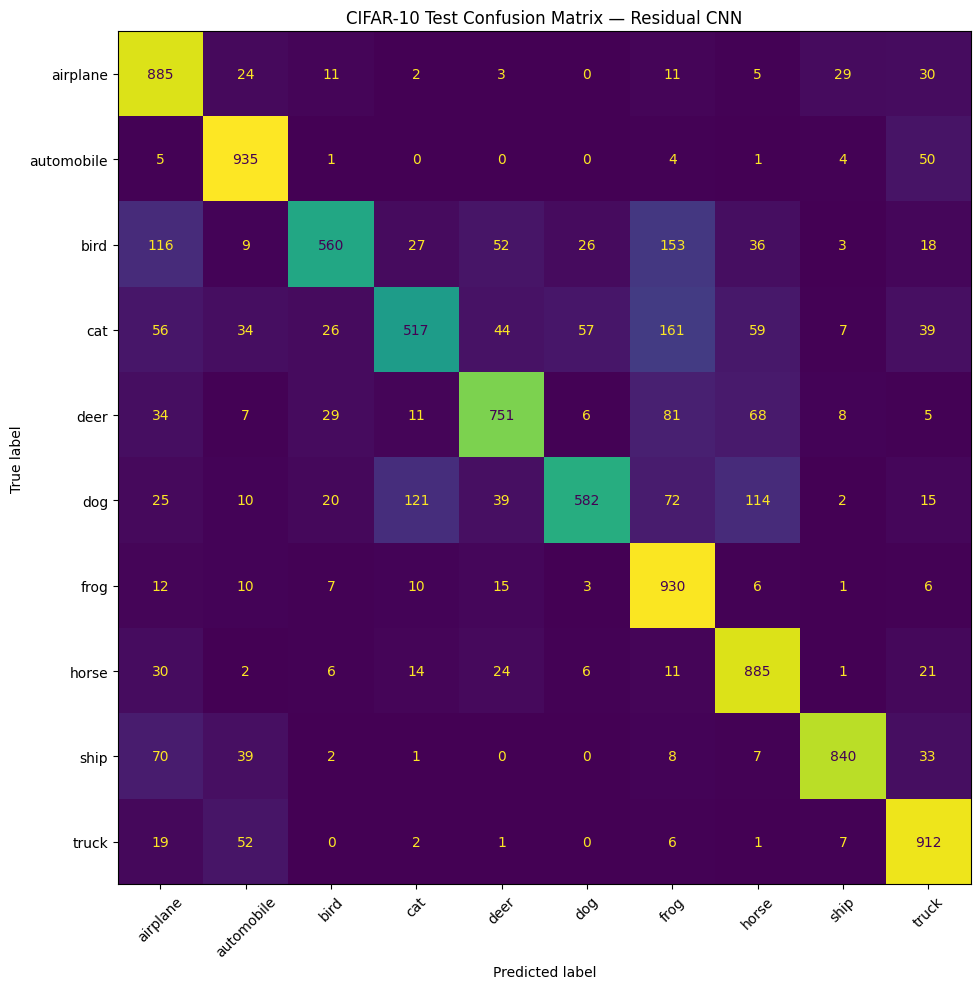

In [53]:
cm = confusion_matrix(all_targets, all_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=test_set.classes)

fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("CIFAR-10 Test Confusion Matrix — Residual CNN")
plt.tight_layout()
plt.show()